# Dry Bean Multi-Class Classification

## BITS Pilani M.Tech AIML – Machine Learning Assignment 2
---
Name: **Deepana Jayachandran**
BITS ID: **2026AK05687**
---


**Dataset:** UCI Dry Bean Dataset - (id 602), Koklu & Ozkan (2020) - https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
**Problem type:** Supervised multi-class classification  
**Target:** `Class` (seven dry bean varieties)

**Problem:** predict the variety of a dry bean (7 classes) from 16 shape measurements taken from an image.

### Project setup

- `data/dry_bean.csv`
- `data/test_data.csv` and a root-level `test_data.csv`
- `model/` – serialized model pipelines (including preprocessing)
- `reports/` – metrics, classification reports, and metadata
- `app.py`, `requirements.txt`, and `README.md`


In [1]:
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn joblib streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [60]:
import json
import warnings
from pathlib import Path

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)

In [62]:
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TEST_SIZE = 0.20

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "model"
REPORT_DIR = PROJECT_DIR / "reports"

for directory in (DATA_DIR, MODEL_DIR, REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR.resolve())

Project directory: F:\GitWS\ml_classification_comparison


In [52]:
# Download the dataset from the UCI repository.
dry_bean = fetch_ucirepo(id=602)

X_raw = dry_bean.data.features.copy()
y_raw = dry_bean.data.targets.copy()

if isinstance(y_raw, pd.DataFrame):
    if y_raw.shape[1] != 1:
        raise ValueError(f"Expected one target column, received: {list(y_raw.columns)}")
    y_raw = y_raw.iloc[:, 0]

target_column = "Class"
X_raw.columns = [str(c).strip() for c in X_raw.columns]
y_raw = y_raw.astype(str).rename(target_column)

df = X_raw.copy()
df[target_column] = y_raw

# Convert feature columns to numeric, raising an error if unexpected text is present.
for col in X_raw.columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

df.to_csv(DATA_DIR / "dry_bean.csv", index=False)

print("Dataset downloaded and saved.")
print("Shape:", df.shape)
print("Input features:", len(X_raw.columns))
print("Target classes:", sorted(df[target_column].unique()))
display(df.head())

Dataset downloaded and saved.
Shape: (13611, 17)
Input features: 16
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Validate dataset requirements

In [53]:
feature_columns = [c for c in df.columns if c != target_column]

validation = {
    "Number of rows": len(df),
    "Number of input features": len(feature_columns),
    "Number of target classes": df[target_column].nunique(),
    "Missing cells": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum())
}
display(pd.Series(validation, name="Value").to_frame())

assert len(df) >= 500, "Dataset must contain at least 500 instances."
assert len(feature_columns) >= 12, "Dataset must contain at least 12 independent input features."
assert df[target_column].nunique() >= 2, "At least two target classes are required."

print("Dataset meets the assignment's minimum size and feature requirements.")
print("\nFeature names:")
for i, name in enumerate(feature_columns, start=1):
    print(f"{i:2}. {name}")

,Value
Number of rows,13611
Number of input features,16
Number of target classes,7
Missing cells,0
Duplicate rows,68


Dataset meets the assignment's minimum size and feature requirements.

Feature names:
 1. Area
 2. Perimeter
 3. MajorAxisLength
 4. MinorAxisLength
 5. AspectRatio
 6. Eccentricity
 7. ConvexArea
 8. EquivDiameter
 9. Extent
10. Solidity
11. Roundness
12. Compactness
13. ShapeFactor1
14. ShapeFactor2
15. ShapeFactor3
16. ShapeFactor4


## Data quality and exploratory data analysis


In [54]:
print("Missing values per column:")
display(df.isna().sum().to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget class counts:")
display(df[target_column].value_counts().rename_axis(target_column).to_frame("Count"))

Missing values per column:


,Missing values
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRatio,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Duplicate rows: 68

Target class counts:


,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


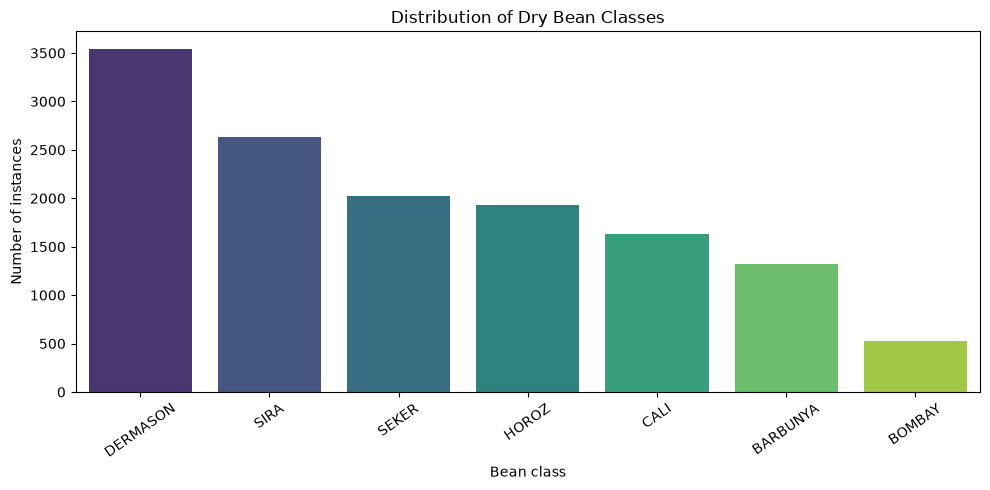

In [55]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x=target_column, order=df[target_column].value_counts().index, palette="viridis")
plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean class")
plt.ylabel("Number of instances")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [56]:
display(df[feature_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


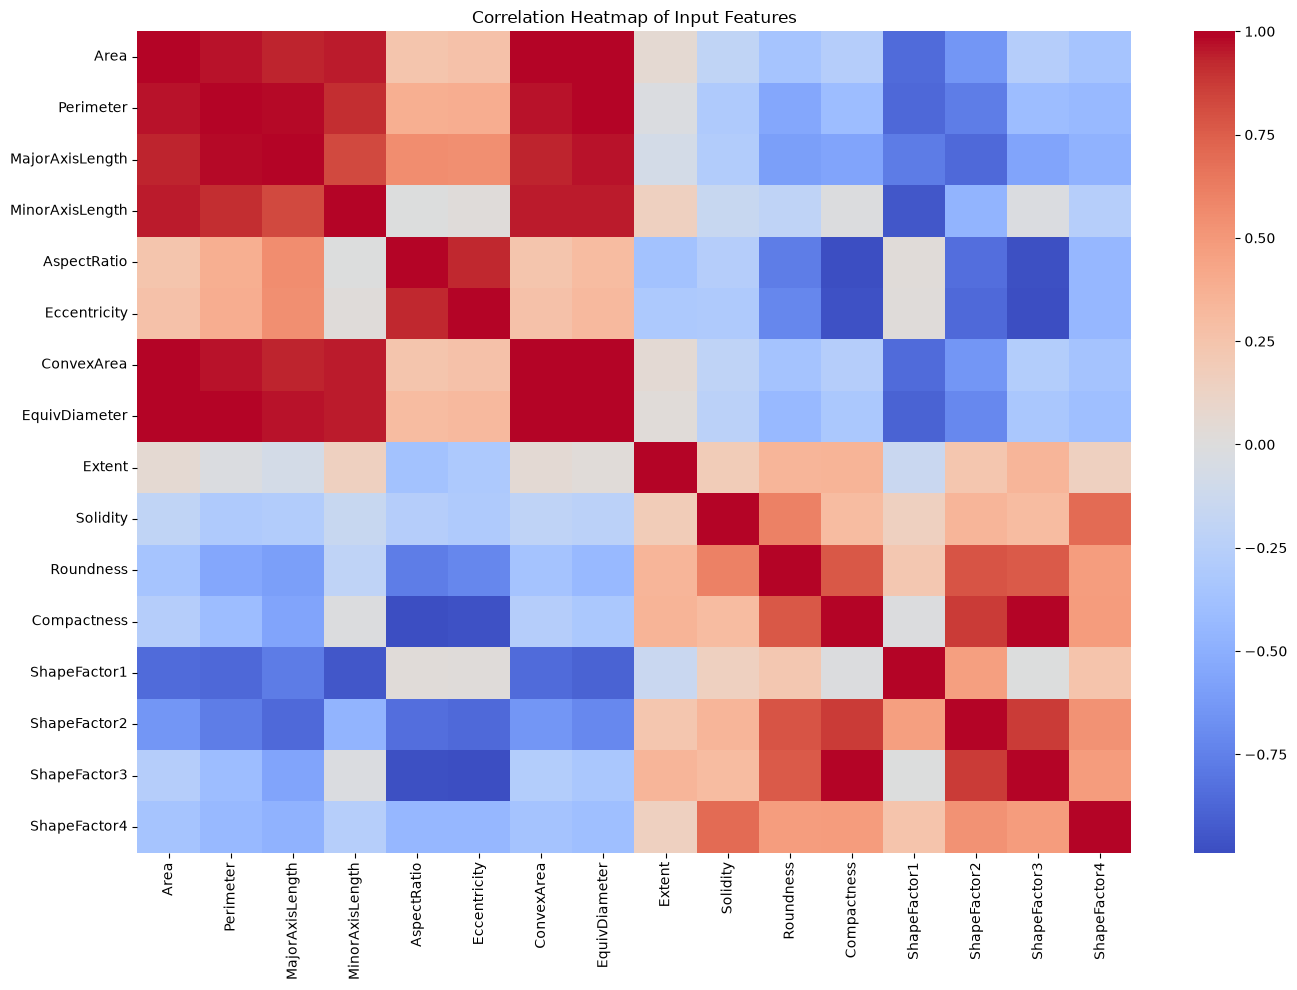

In [57]:
plt.figure(figsize=(14, 10))
sns.heatmap(df[feature_columns].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Input Features")
plt.tight_layout()
plt.show()

## 3. Prepare the data and split into training and test sets

Use the same 80:20 stratified split for every model. Stratification preserves the approximate class proportions in both subsets. `random_state=42` makes the split reproducible.

Preprocessing is placed inside each scikit-learn Pipeline. This prevents the imputer and scaler from learning information from the test data.

In [58]:
X = df[feature_columns].copy()
y = df[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training records: {len(X_train)}")
print(f"Testing records : {len(X_test)}")
print("\nTraining proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("Train proportion").to_frame())
print("\nTesting proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("Test proportion").to_frame())

# Assignment requires a test CSV containing features and the true target.
test_data = X_test.copy()
test_data[target_column] = y_test
test_data.to_csv(DATA_DIR / "test_data.csv", index=False)
test_data.to_csv(PROJECT_DIR / "test_data.csv", index=False)
print("\nSaved data/test_data.csv and test_data.csv")

Training records: 10888
Testing records : 2723

Training proportions:


,Train proportion
Class,
BARBUNYA,0.097079
BOMBAY,0.038391
CALI,0.119765
DERMASON,0.260562
HOROZ,0.141624
SEKER,0.148880
SIRA,0.193699



Testing proportions:


,Test proportion
Class,
BARBUNYA,0.097319
BOMBAY,0.038193
CALI,0.119721
DERMASON,0.260375
HOROZ,0.141755
SEKER,0.149100
SIRA,0.193537



Saved data/test_data.csv and test_data.csv


## 4. The Five classifiers - Define & Standardize required classifiers

- **Logistic Regression:** linear classification model.
- **Decision Tree:** rule-based model that splits feature space.
- **KNN:** predicts using nearby training observations.
- **Gaussian Naive Bayes:** probabilistic classifier using Gaussian feature likelihoods.
- **SVM:** support vector classifier; RBF kernel is used here.

Standardization is applied to Logistic Regression, KNN, and SVM because they are sensitive to feature scales. Decision Tree and Gaussian Naive Bayes are not scaled in this setup. Median imputation is included in all pipelines for a consistent, safe preprocessing workflow.

In [36]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(C=10, max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=11, weights="distance"))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("power", PowerTransformer()),
        ("classifier", GaussianNB(var_smoothing=1e-9))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=RANDOM_STATE))
    ])
}

print("Configured models:")
for model_name in models:
    print("-", model_name)

Configured models:
- Logistic Regression
- Decision Tree
- KNN
- Gaussian Naive Bayes
- SVM


## 5. Train and evaluate the five models

Metrics:
- Accuracy
- AUC (weighted one-vs-rest for multi-class classification)
- Precision (weighted)
- Recall (weighted)
- F1 Score (weighted)
- Matthews Correlation Coefficient (MCC)

Weighted averaging accounts for the number of true instances in each class. AUC requires class probabilities, so the SVM is configured with `probability=True`.

In [37]:
results = []
predictions_by_model = {}
probabilities_by_model = {}
classification_reports = {}

for model_name, pipeline in models.items():
    print(f"Fitting {model_name} ...")
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)

    predictions_by_model[model_name] = y_pred
    probabilities_by_model[model_name] = y_prob

    auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="weighted",
        labels=pipeline.classes_
    )

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }
    results.append(row)

    report_text = classification_report(y_test, y_pred, zero_division=0)
    classification_reports[model_name] = report_text

    filename = model_name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipeline, MODEL_DIR / filename)
    (REPORT_DIR / (filename.replace(".joblib", "_classification_report.txt"))).write_text(
        report_text, encoding="utf-8"
    )

metrics_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False).reset_index(drop=True)
metrics_df.to_csv(REPORT_DIR / "model_metrics.csv", index=False)

print("\nEvaluation comparison:")
display(metrics_df.round(4))

Fitting Logistic Regression ...
Fitting Decision Tree ...
Fitting KNN ...
Fitting Gaussian Naive Bayes ...
Fitting SVM ...

Evaluation comparison:


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,SVM,0.9243,0.9933,0.9243,0.9243,0.9243,0.9085
1,Logistic Regression,0.9218,0.9935,0.9228,0.9218,0.9220,0.9055
2,KNN,0.9185,0.9861,0.9192,0.9185,0.9186,0.9014
3,Decision Tree,0.9064,0.9725,0.9063,0.9064,0.9062,0.8867
4,Gaussian Naive Bayes,0.8972,0.9900,0.9007,0.8972,0.8973,0.8766


## 6. Compare model performance

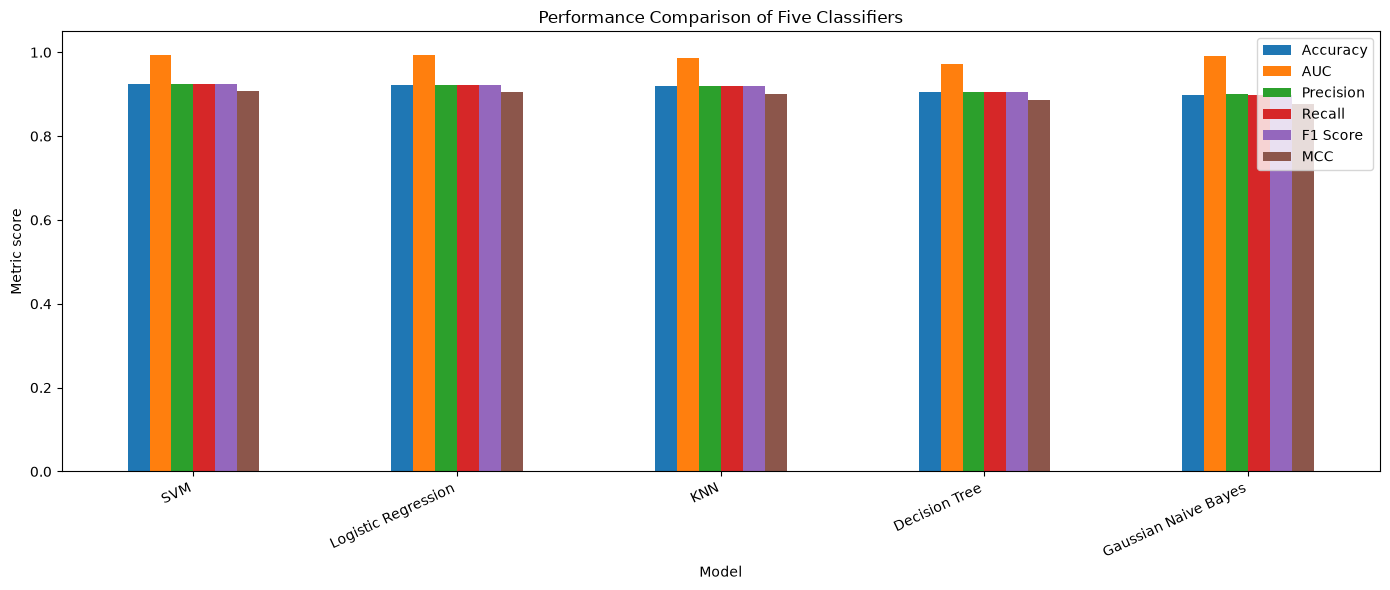

Best model by weighted F1 Score:


Model             SVM
Accuracy     0.924348
AUC          0.993279
Precision     0.92432
Recall       0.924348
F1 Score     0.924295
MCC          0.908504
Name: 0, dtype: object

In [41]:
plot_df = metrics_df.set_index("Model")[["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]]
ax = plot_df.plot(kind="bar", figsize=(14, 6))
ax.set_title("Performance Comparison of Five Classifiers")
ax.set_ylabel("Metric score")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print("Best model by weighted F1 Score:")
display(metrics_df.iloc[0])

## 7. Confusion matrix and detailed classification report


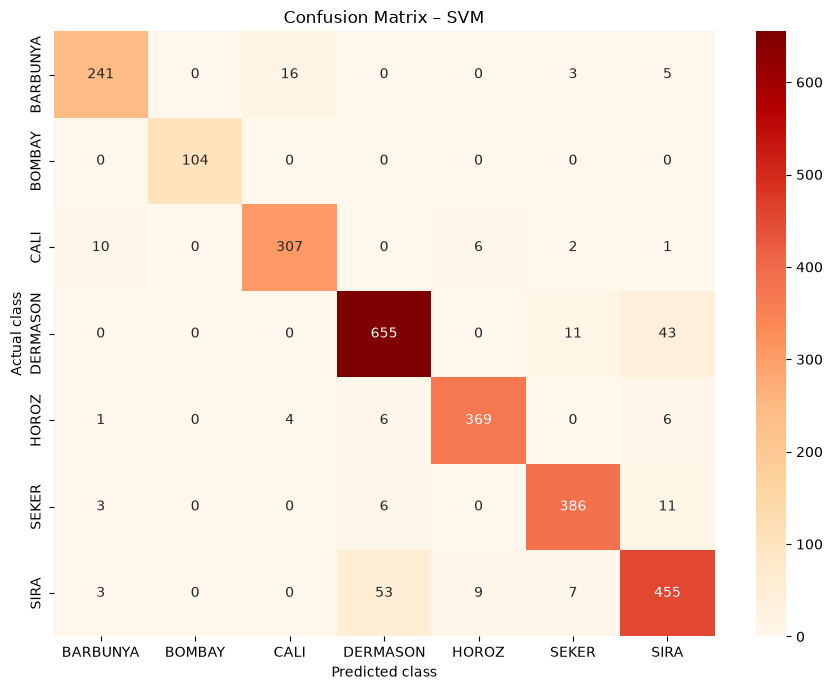

Selected model: SVM
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.91      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.91      0.92      0.92       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.95       406
        SIRA       0.87      0.86      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.92      0.92      0.92      2723



In [48]:
best_model_name = metrics_df.iloc[0]["Model"]
best_model = models[best_model_name]
best_predictions = predictions_by_model[best_model_name]
labels = best_model.classes_

cm = confusion_matrix(y_test, best_predictions, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="OrRd",
    xticklabels=labels, yticklabels=labels
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(f"Confusion Matrix – {best_model_name}")
plt.tight_layout()
plt.show()

print("Selected model:", best_model_name)
print(classification_reports[best_model_name])

### Final Model Comparison Summary
The table below summarizes all five classifiers using the six assignment metrics. The highest value in each metric column is highlighted. The overall recommendation is based primarily on weighted F1 Score, with Accuracy, AUC, and MCC considered as supporting metrics.

In [59]:
# Final comparison table
summary_metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]

summary_df = metrics_df[["Model"] + summary_metrics].copy()
summary_df = summary_df.sort_values("F1 Score", ascending=False).reset_index(drop=True)
summary_df.insert(0, "Rank", range(1, len(summary_df) + 1))

display(
    summary_df.style
    .format({metric: "{:.4f}" for metric in summary_metrics})
    .highlight_max(subset=summary_metrics, color="#d8f3dc")
    .set_caption("----------Final Comparison of Classification Models------------")
)

# Identify the best-performing model for each metric.
metric_winners = []
for metric in summary_metrics:
    winner = metrics_df.loc[metrics_df[metric].idxmax()]
    metric_winners.append({
        "Evaluation Metric": metric,
        "Best Model": winner["Model"],
        "Score": winner[metric]
    })

metric_winners_df = pd.DataFrame(metric_winners)
display(
    metric_winners_df.style
    .format({"Score": "{:.4f}"})
    .set_caption("---------Best Performing Model by Metric--------")
)

# Overall recommendation: model with the highest weighted F1 Score.
best_overall = metrics_df.loc[metrics_df["F1 Score"].idxmax()]
best_auc = metrics_df.loc[metrics_df["AUC"].idxmax()]

print("OVERALL MODEL COMPARISON SUMMARY")
print("-" * 45)
print(f"Recommended model (highest weighted F1 Score): {best_overall['Model']}")
print(f"Accuracy : {best_overall['Accuracy']:.4f}")
print(f"AUC      : {best_overall['AUC']:.4f}")
print(f"Precision: {best_overall['Precision']:.4f}")
print(f"Recall   : {best_overall['Recall']:.4f}")
print(f"F1 Score : {best_overall['F1 Score']:.4f}")
print(f"MCC      : {best_overall['MCC']:.4f}")

if best_auc["Model"] != best_overall["Model"]:
    print(
        f"Note: {best_auc['Model']} achieved the highest AUC "
        f"({best_auc['AUC']:.4f}), while {best_overall['Model']} "
        f"achieved the highest weighted F1 Score."
    )

,Rank,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,1,SVM,0.9243,0.9933,0.9243,0.9243,0.9243,0.9085
1,2,Logistic Regression,0.9218,0.9935,0.9228,0.9218,0.9220,0.9055
2,3,KNN,0.9185,0.9861,0.9192,0.9185,0.9186,0.9014
3,4,Decision Tree,0.9064,0.9725,0.9063,0.9064,0.9062,0.8867
4,5,Gaussian Naive Bayes,0.8972,0.9900,0.9007,0.8972,0.8973,0.8766


,Evaluation Metric,Best Model,Score
0,Accuracy,SVM,0.9243
1,AUC,Logistic Regression,0.9935
2,Precision,SVM,0.9243
3,Recall,SVM,0.9243
4,F1 Score,SVM,0.9243
5,MCC,SVM,0.9085


OVERALL MODEL COMPARISON SUMMARY
---------------------------------------------
Recommended model (highest weighted F1 Score): SVM
Accuracy : 0.9243
AUC      : 0.9933
Precision: 0.9243
Recall   : 0.9243
F1 Score : 0.9243
MCC      : 0.9085
Note: Logistic Regression achieved the highest AUC (0.9935), while SVM achieved the highest weighted F1 Score.
